# 1. Đọc và chạy dataset

In [3]:
import pandas as pd

data_path = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/processed/citation_ml_dataset.parquet"

df = pd.read_parquet(data_path)
print(f"Kích thước: {df.shape}")

Kích thước: (694450, 13)


# 2. In 5 dòng đầu tiên

In [4]:
df.head()

,paper_id,pub_year,past_in_degree,num_authors,num_topics,pagerank_score,paper_age,citation_velocity,paper_feat_128d,delta_c,ogb_split,label,temporal_split
0,4560,2018,6,2,11,0.553001,1,6.0,"{'type': 1, 'size': None, 'indices': None, 'va...",4,valid,1.0,test
1,10072,2018,16,2,10,1.505708,1,16.0,"{'type': 1, 'size': None, 'indices': None, 'va...",0,valid,0.0,test
2,10489,2018,3,2,9,0.653877,1,3.0,"{'type': 1, 'size': None, 'indices': None, 'va...",5,valid,1.0,test
3,29534,2018,0,1,11,0.386840,1,0.0,"{'type': 1, 'size': None, 'indices': None, 'va...",0,valid,0.0,test
4,35691,2018,70,3,11,1.967854,1,70.0,"{'type': 1, 'size': None, 'indices': None, 'va...",22,valid,1.0,test


# 3. Đếm số lượng label = 1 và label = 0

In [5]:
df[df['label'] == 0].count()

paper_id             649837
pub_year             649837
past_in_degree       649837
num_authors          649837
num_topics           649837
pagerank_score       649837
paper_age            649837
citation_velocity    649837
paper_feat_128d      649837
delta_c              649837
ogb_split            649837
label                649837
temporal_split       649837
dtype: int64

In [6]:
df[df['label'] == 1].count()

paper_id             44613
pub_year             44613
past_in_degree       44613
num_authors          44613
num_topics           44613
pagerank_score       44613
paper_age            44613
citation_velocity    44613
paper_feat_128d      44613
delta_c              44613
ogb_split            44613
label                44613
temporal_split       44613
dtype: int64

In [11]:
df.groupby('temporal_split')['label'].value_counts(normalize=True)

temporal_split  label
test            0.0      0.864255
                1.0      0.135745
train           0.0      0.948135
                1.0      0.051865
valid           0.0      0.903217
                1.0      0.096783
Name: proportion, dtype: float64

### Mất cân bằng giữa label 1 và label 0

# 4. Đếm số lượng từng tập train/test/valid

In [10]:
dem_test = df[df["temporal_split"] == "test"]["temporal_split"].count()
dem_train = df[df["temporal_split"] == "train"]["temporal_split"].count()
dem_valid = df[df["temporal_split"] == "valid"]["temporal_split"].count()

print("Số lượng dataset của bộ test:", dem_test)
print("Số lượng dataset của bộ train:", dem_train)
print("Số lượng dataset của bộ valid:", dem_valid)

Số lượng dataset của bộ test: 64879
Số lượng dataset của bộ train: 559373
Số lượng dataset của bộ valid: 70198


# 5. Tương quan đặc trưng đồ thị vs Tăng trưởng trích dẫn


<Axes: xlabel='pagerank_score', ylabel='delta_c'>

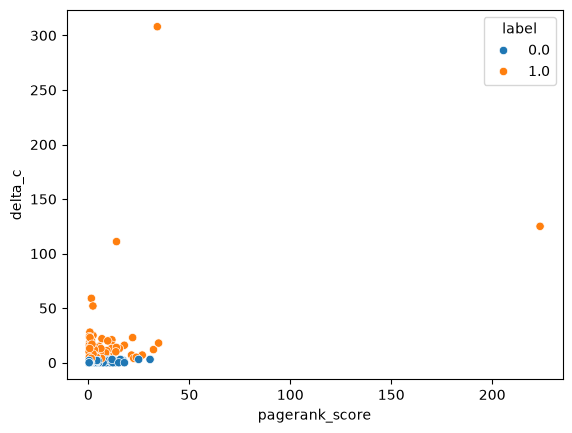

In [14]:
import seaborn as sns

sns.scatterplot(data=df.sample(5000), x='pagerank_score', y='delta_c', hue='label')

# 6. Vòng đời bài báo (paper_age) & Tốc độ trích dẫn (citation_velocity)

<Axes: xlabel='paper_age'>

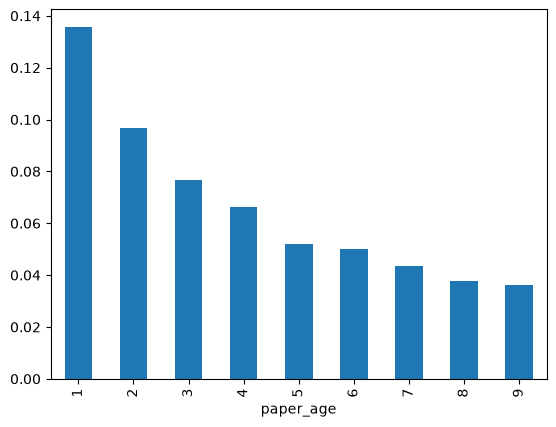

In [15]:
df.groupby('paper_age')['label'].mean().plot(kind='bar')

# 7. Tác động của số tác giả & chủ đề


In [16]:
df.groupby('label')[['num_authors', 'num_topics']].mean()

,num_authors,num_topics
label,,
0.0,8.240708,10.236447
1.0,26.095331,10.350301


# 8. Ma trận tương quan (Correlation Heatmap)


<Axes: >

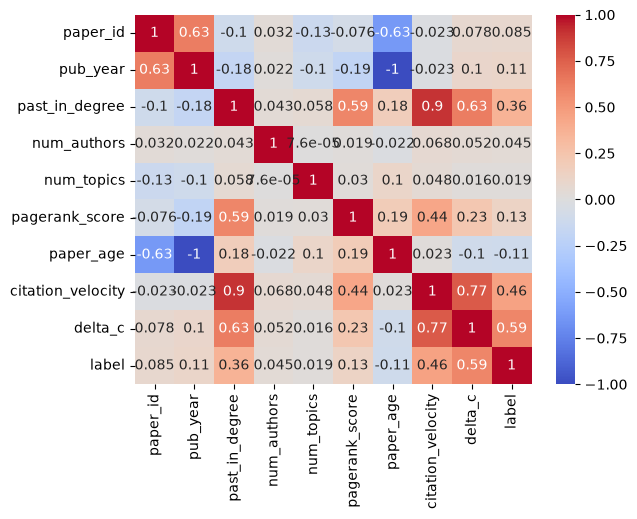

In [17]:
sns.heatmap(df.drop(columns=['paper_feat_128d']).corr(numeric_only=True), annot=True, cmap='coolwarm')

# 9. Lọc top 10 bài có trích dẫn quá khứ thấp (past_in_degree nhỏ) nhưng tăng trưởng tương lai đột biến (delta_c lớn).

In [18]:
df[df['past_in_degree'] < 10].sort_values('delta_c', ascending=False).head(10)


,paper_id,pub_year,past_in_degree,num_authors,num_topics,pagerank_score,paper_age,citation_velocity,paper_feat_128d,delta_c,ogb_split,label,temporal_split
2604,666013,2018,7,3,11,0.463466,1,7.0,"{'type': 1, 'size': None, 'indices': None, 'va...",63,valid,1.0,test
64601,694961,2018,5,2,10,0.508310,1,5.0,"{'type': 1, 'size': None, 'indices': None, 'va...",54,valid,1.0,test
21495,641641,2018,6,5,11,0.637207,1,6.0,"{'type': 1, 'size': None, 'indices': None, 'va...",52,valid,1.0,test
64640,706501,2018,9,328,8,0.741219,1,9.0,"{'type': 1, 'size': None, 'indices': None, 'va...",49,valid,1.0,test
2448,663429,2018,9,6,11,0.628810,1,9.0,"{'type': 1, 'size': None, 'indices': None, 'va...",48,valid,1.0,test
63688,670615,2018,9,10,10,0.627809,1,9.0,"{'type': 1, 'size': None, 'indices': None, 'va...",46,valid,1.0,test
43933,680030,2018,8,13,10,0.474376,1,8.0,"{'type': 1, 'size': None, 'indices': None, 'va...",44,valid,1.0,test
64439,687142,2018,2,47,11,0.469044,1,2.0,"{'type': 1, 'size': None, 'indices': None, 'va...",42,valid,1.0,test
43005,661738,2018,3,4,8,0.410975,1,3.0,"{'type': 1, 'size': None, 'indices': None, 'va...",41,valid,1.0,test
7548,684767,2018,0,78,11,0.386840,1,0.0,"{'type': 1, 'size': None, 'indices': None, 'va...",40,valid,1.0,test
